# 18. Análise de experimentos com SQL

**Objetivo e requisitos.** Gravar vários experimentos num banco SQLite com `ExperimentStore` e analisar os resultados com consultas: campeões, erro por família, decisões da seleção, custo, erro por origem e avaliação externa. Duas séries offline (uma com estrutura, outra só ruído) nos protocolos A e B dão quatro execuções. Extras `stats` e `plot`; nenhum download.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Dados e protocolo

`synthetic_daily` tem tendência, ciclo semanal e ruído AR(1), estrutura que um corretor de resíduos pode aproveitar; `white_noise_daily` é nível mais ruído branco, em que nada além da média é previsível. Cada série roda nos protocolos A (7 passos de uma vez) e B (um passo por vez), com o mesmo espaço de busca pequeno.

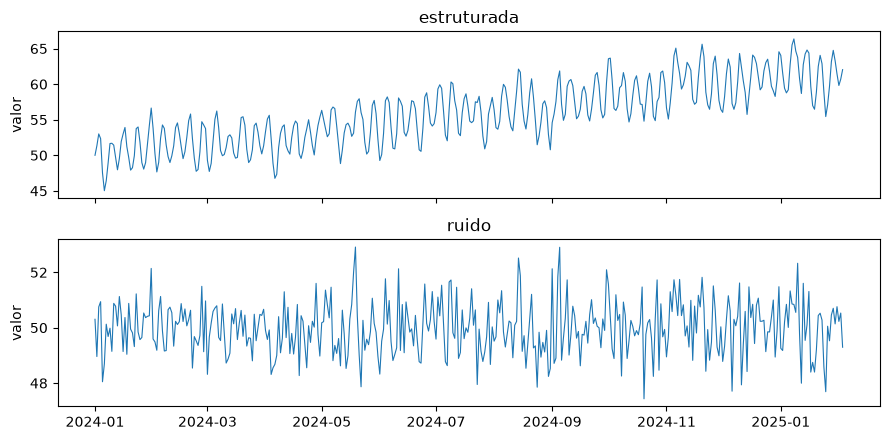

In [2]:
SERIES = {
    "estruturada": get_data("synthetic_daily", n=400),
    "ruido": get_data("white_noise_daily", n=400),
}
SETTINGS = {
    "fh": 7,
    "session_id": 42,
    "budget": "smoke",
    "base_models": ["naive", "seasonal_naive", "linear", "knn", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for ax, (name, y) in zip(axes, SERIES.items(), strict=True):
    ax.plot(y.index, y.to_numpy(), linewidth=0.8)
    ax.set(title=name, ylabel="valor")
fig.tight_layout()
plt.show()

## 2. Registro dos experimentos

O banco fica em `artifacts/`, fora do git, e é recriado a cada execução do notebook. Cada experimento é comparado, finalizado, avaliado uma vez no teste selado e registrado com etiquetas; `values=True` grava também as previsões e as observações do teste, usadas na seção 4.

In [3]:
path = Path("artifacts/experimentos.db")
path.unlink(missing_ok=True)
store = ExperimentStore(path)

for name, y in SERIES.items():
    for variant in ("A", "B"):
        exp = AutoHybridExperiment(variant=variant, **SETTINGS).fit(y)
        best = exp.compare_models().best
        final = exp.finalize_model(best)
        exp.evaluate_external(final)
        store.log(
            exp,
            name=f"{name}-{variant}",
            tags={"serie": name, "protocolo": variant},
            models=[final],
            values=True,
        )
store.runs()[["name", "variant", "n_origins", "ranking_metric", "champion_label"]]

,name,variant,n_origins,ranking_metric,champion_label
0,ruido-B,B,14,MASE,exponential_smoothing(season_length=7)
1,ruido-A,A,14,MASE,exponential_smoothing(season_length=7)
2,estruturada-B,B,14,MASE,exponential_smoothing(season_length=7) + linea...
3,estruturada-A,A,14,MASE,exponential_smoothing(season_length=7)


In [4]:
store.query(
    """
    SELECT name AS tabela FROM sqlite_master WHERE type = 'table' ORDER BY name
    """
)

,tabela
0,candidates
1,decisions
2,evaluations
3,events
4,external
5,ledger
6,meta
7,metrics
8,models
9,predictions


## 3. Consultas

### Campeões e placar

Para cada execução, o campeão, o seu erro médio na camada de seleção e quantas candidatas a busca avaliou.

In [5]:
store.query(
    """
    SELECT r.name,
           r.champion_label AS campeao,
           ROUND(m.value, 3) AS mase_selecao,
           (SELECT COUNT(*) FROM ledger l
             WHERE l.run_id = r.run_id AND l.status = 'EVALUATED') AS avaliadas
    FROM runs r
    JOIN metrics m
      ON m.run_id = r.run_id AND m.candidate_id = r.champion_id
     AND m.layer = 'select' AND m.metric = r.ranking_metric
    ORDER BY r.name
    """
)

,name,campeao,mase_selecao,avaliadas
0,estruturada-A,exponential_smoothing(season_length=7),0.790,9
1,estruturada-B,exponential_smoothing(season_length=7) + linea...,0.652,9
2,ruido-A,exponential_smoothing(season_length=7),0.865,9
3,ruido-B,exponential_smoothing(season_length=7),0.865,9


In [6]:
run_id = store.query("SELECT run_id FROM runs WHERE name = ?", ("estruturada-A",)).run_id[0]
store.query(
    """
    SELECT c.label, c.family, ROUND(m.value, 3) AS mase, e.coverage, e.is_champion
    FROM metrics m
    JOIN candidates c USING (run_id, candidate_id)
    JOIN evaluations e USING (run_id, candidate_id, layer)
    WHERE m.run_id = ? AND m.layer = 'select' AND m.metric = 'MASE'
    ORDER BY mase
    """,
    (run_id,),
)

,label,family,mase,coverage,is_champion
0,exponential_smoothing(season_length=7),statistical,0.790,1.0,1
1,exponential_smoothing(season_length=7) + linea...,residual,0.794,1.0,0
2,knn(lags=7),kernel,0.969,1.0,0
3,linear(lags=7),linear,0.987,1.0,0


### Erro por família

Erro médio de cada família na camada de busca, por execução. A consulta agrega em SQL e o pandas só gira a tabela para o gráfico.

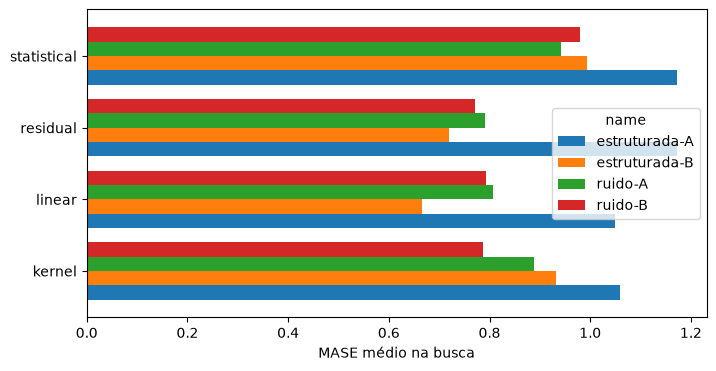

name,estruturada-A,estruturada-B,ruido-A,ruido-B
family,,,,
kernel,1.059,0.931,0.889,0.787
linear,1.049,0.666,0.806,0.794
residual,1.173,0.720,0.791,0.772
statistical,1.173,0.994,0.941,0.980


In [7]:
families = store.query(
    """
    SELECT r.name, c.family, AVG(m.value) AS mase, COUNT(*) AS candidatas
    FROM metrics m
    JOIN candidates c USING (run_id, candidate_id)
    JOIN runs r USING (run_id)
    WHERE m.layer = 'search' AND m.metric = 'MASE'
    GROUP BY r.name, c.family
    """
)
table = families.pivot(index="family", columns="name", values="mase")
ax = table.plot.barh(figsize=(8, 4), width=0.8)
ax.set(xlabel="MASE médio na busca", ylabel="")
plt.show()
table.round(3)

### Decisões da seleção

Cada desafiante comparado com o campeão da vez: aceito ou rejeitado, e por quê. Na série de ruído, um corretor não deveria ser aceito; quando é, o ganho mediano e a taxa de vitórias mostram por quão pouco.

In [8]:
store.query(
    """
    SELECT r.name, d.family, d.challenger_label AS desafiante, d.accepted AS aceito,
           ROUND(d.median_gain, 3) AS ganho_mediano, ROUND(d.win_rate, 2) AS vitorias,
           d.reason_codes AS motivos
    FROM decisions d JOIN runs r USING (run_id)
    ORDER BY r.name, d.step
    """
)

,name,family,desafiante,aceito,ganho_mediano,vitorias,motivos
0,estruturada-A,linear,linear(lags=7),0,-0.061,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
1,estruturada-A,kernel,knn(lags=7),0,-0.424,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
2,estruturada-A,residual,exponential_smoothing(season_length=7) + linea...,0,0.003,0.57,"[""median_gain_below_threshold"", ""win_rate_belo..."
3,estruturada-B,linear,linear(lags=7),0,-0.076,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
4,estruturada-B,kernel,knn(lags=7),0,-0.035,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
5,estruturada-B,residual,exponential_smoothing(season_length=7) + linea...,1,0.052,0.71,"[""accepted""]"
6,ruido-A,linear,linear(lags=7),0,-0.025,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."
7,ruido-A,kernel,knn(lags=7),0,-0.040,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
8,ruido-A,residual,exponential_smoothing(season_length=7) + linea...,0,0.015,0.57,"[""median_gain_below_threshold"", ""win_rate_belo..."
9,ruido-B,linear,linear(lags=7),0,-0.055,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."


In [9]:
store.query(
    """
    SELECT reason_codes AS motivo, COUNT(*) AS n
    FROM decisions WHERE accepted = 0
    GROUP BY reason_codes ORDER BY n DESC
    """
)

,motivo,n
0,"[""median_gain_below_threshold"", ""win_rate_belo...",11


### Custo e erro

Tempo de ajuste somado nas origens contra o erro na busca, uma marca por candidata. Mais custo não garante menos erro.

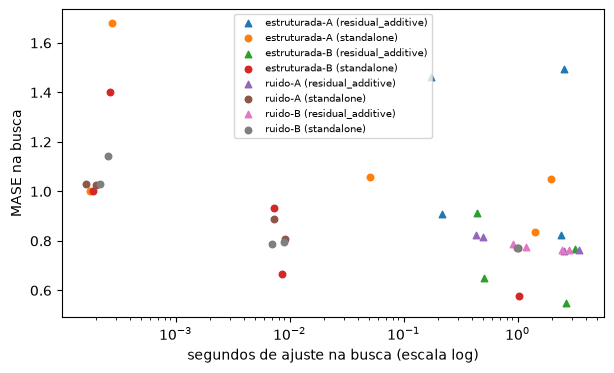

In [10]:
cost = store.query(
    """
    SELECT r.name, c.label, c.strategy, SUM(t.fit_seconds) AS segundos, m.value AS mase
    FROM trials t
    JOIN candidates c USING (run_id, candidate_id)
    JOIN runs r USING (run_id)
    JOIN metrics m
      ON m.run_id = t.run_id AND m.candidate_id = t.candidate_id
     AND m.layer = 'search' AND m.metric = 'MASE'
    WHERE t.layer = 'search'
    GROUP BY t.run_id, t.candidate_id
    """
)
fig, ax = plt.subplots(figsize=(7, 4))
for (name, strategy), part in cost.groupby(["name", "strategy"]):
    ax.scatter(
        part.segundos,
        part.mase,
        s=22,
        marker="o" if strategy == "standalone" else "^",
        label=f"{name} ({strategy})",
    )
ax.set(xscale="log", xlabel="segundos de ajuste na busca (escala log)", ylabel="MASE na busca")
ax.legend(fontsize=7)
plt.show()

### Erro por origem

As métricas de cada origem ficam em `trial_metrics`. Aqui, o campeão contra a persistência em cada origem da camada de seleção: o ganho do campeão é consistente ou depende de poucas origens?

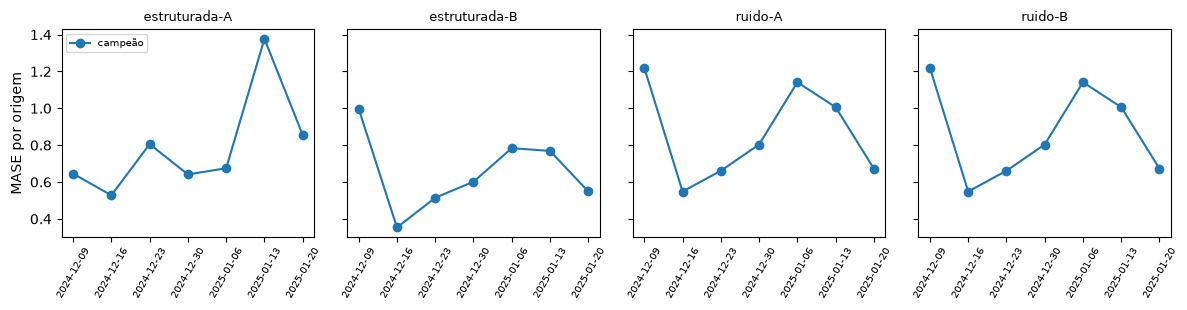

In [11]:
origins = store.query(
    """
    SELECT r.name, t.origin, c.label, tm.value AS mase,
           t.candidate_id = r.champion_id AS campeao
    FROM trial_metrics tm
    JOIN trials t USING (run_id, candidate_id, unit_id)
    JOIN candidates c USING (run_id, candidate_id)
    JOIN runs r USING (run_id)
    WHERE t.layer = 'select' AND tm.metric = 'MASE'
      AND (t.candidate_id = r.champion_id OR c.label = 'naive')
    ORDER BY r.name, t.origin
    """
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, part) in zip(axes, origins.groupby("name"), strict=True):
    for is_champion, rows in part.groupby("campeao"):
        ax.plot(
            rows.origin.str[:10], rows.mase, marker="o", label="campeão" if is_champion else "naive"
        )
    ax.set_title(name, fontsize=9)
    ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0].set_ylabel("MASE por origem")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 4. Avaliação externa

O erro do campeão na seleção contra o erro no teste selado. Uma diferença grande indica que a validação foi otimista; o banco permite acompanhar isso em muitas execuções.

In [12]:
store.query(
    """
    SELECT r.name,
           ROUND(m.value, 3) AS mase_selecao,
           ROUND(x.value, 3) AS mase_teste,
           ROUND(x.value - m.value, 3) AS diferenca
    FROM runs r
    JOIN metrics m
      ON m.run_id = r.run_id AND m.candidate_id = r.champion_id
     AND m.layer = 'select' AND m.metric = 'MASE'
    JOIN models mo ON mo.run_id = r.run_id
    JOIN external x
      ON x.run_id = r.run_id AND x.model_id = mo.model_id AND x.metric = 'MASE'
    ORDER BY r.name
    """
)

,name,mase_selecao,mase_teste,diferenca
0,estruturada-A,0.790,1.627,0.838
1,estruturada-B,0.652,0.552,-0.101
2,ruido-A,0.865,0.502,-0.362
3,ruido-B,0.865,0.502,-0.362


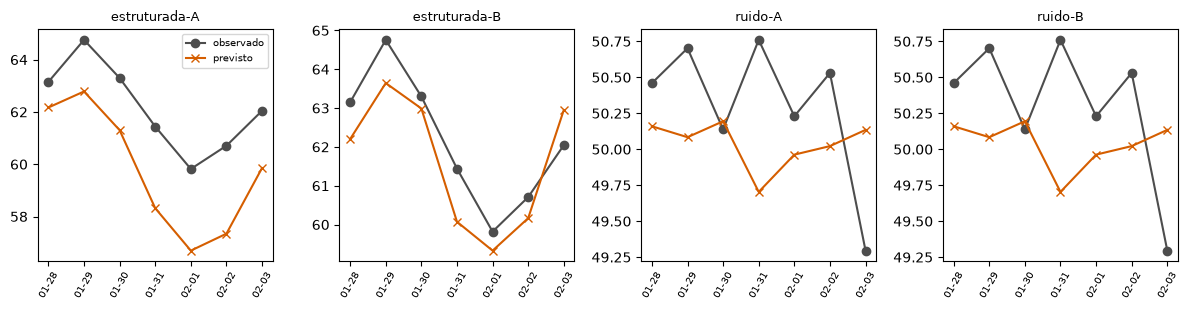

In [13]:
forecasts = store.query(
    """
    SELECT r.name, p.timestamp, p.y_pred, p.y_true
    FROM predictions p JOIN runs r USING (run_id)
    ORDER BY r.name, p.timestamp
    """
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (name, part) in zip(axes, forecasts.groupby("name"), strict=True):
    ax.plot(part.timestamp.str[5:10], part.y_true, marker="o", color="0.3", label="observado")
    ax.plot(part.timestamp.str[5:10], part.y_pred, marker="x", color="#D55E00", label="previsto")
    ax.set_title(name, fontsize=9)
    ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 5. Leitura

- **Um banco, quatro execuções.** As 15 tabelas guardam desde a identidade das séries até cada origem de cada candidata; as perguntas abaixo foram respondidas só com SQL, sem refazer nenhum experimento.
- **Campeões.** O ETS foi o campeão em três execuções. Só na série estruturada, no protocolo B, o híbrido ETS + corretor linear entrou: ganho mediano de 0,052 e 71 % de vitórias, logo acima do limiar (0,05 e 60 %).
- **Ruído.** Na série de ruído branco, nenhum corretor foi aceito nos dois protocolos: os ganhos medianos ficaram entre 0,012 e 0,015, abaixo do limiar. É o comportamento esperado da regra de aceite.
- **Motivos.** Todas as 11 rejeições tiveram o mesmo motivo: ganho mediano e taxa de vitórias abaixo do limiar. Os modelos sobre lags (linear e KNN) perderam do ETS em todas as execuções.
- **Custo.** A candidata mais cara de cada execução, o ETS com corretor sobre resíduos multipasso (2,6 a 3,5 s de ajuste na busca), nunca teve o menor erro. Na série estruturada, protocolo B, a regressão linear sobre 7 lags levou 0,01 s e ficou a 0,12 de MASE da melhor.
- **Validação × teste.** Na série estruturada, protocolo A, o MASE subiu de 0,79 na seleção para 1,63 no teste selado; nas outras execuções, o teste ficou abaixo da seleção. Com um teste de 7 pontos, a diferença varia muito de uma janela para outra; o banco permite acompanhar essa diferença ao longo de muitas execuções.
- **Uso.** Para analisar outros experimentos, basta registrá-los no mesmo arquivo com `store.log` e repetir as consultas, filtrando por `name` ou pelas etiquetas em `runs.tags`.